# 七个数据集：读取、NaN 检查与重复清洗

本步只准备数据，不训练、不编码标签、不筛选 arXiv 九大类别、不重新划分训练集。

清洗后的变量：`df_financial`、`df_envdata`、`df_acgnews`、`df_ecthr`、`df_ohsumed`、`df_rheology`、`df_arxiv`。
统一列：`document_id`、`text`、`labels`（类别名称列表）、`source_splits`、`source_document_ids`。
来源拆分仅作追溯；后续训练必须另外确定 split/CV 方案，不能直接把这些汇总 DF 当作训练集。

清洗规则：只规范空白，不改大小写或标点。移除缺失/空文本和无效标签；ECtHR 的空列表表示无违反条款，合法保留。
按规范文本去重：多标签合并标签；单标签同文异标进入 `df_label_conflicts`，不混入清洁 DF。
`source_splits` 和 `source_document_ids` 保留重复记录原来的所有来源；不改写原始数据文件。


In [2]:
from pathlib import Path
from collections import defaultdict
import ast
import numpy as np
import pandas as pd
from datasets import load_from_disk
from IPython.display import display

BASE_DIR = Path.cwd()
if (BASE_DIR / "Standardizing").is_dir():
    BASE_DIR = BASE_DIR / "Standardizing"
if not (BASE_DIR / "Financial" / "financial_original.csv").exists():
    raise FileNotFoundError("请从 GR 项目根目录或 Standardizing 目录运行此 Notebook。")

pd.set_option("display.max_colwidth", 100)
print("Data directory:", BASE_DIR)


Data directory: /home/amyliu/Desktop/GR/Standardizing


In [3]:
def label_list(value):
    """缺失标签为 None；空列表保持空列表，与缺失值区分。"""
    if isinstance(value, (list, tuple, set, np.ndarray)):
        if any(pd.isna(item) for item in value):
            return None
        labels = [str(item).strip() for item in value]
        return sorted(set(labels)) if all(labels) else None
    if value is None or pd.isna(value):
        return None
    value = str(value).strip()
    return [value] if value else None


def to_frame(frame, dataset_name, text_col, label_col, source_split, id_col=None):
    result = pd.DataFrame(index=frame.index)
    # split 前缀使 Rheology 等数据集中局部 ID 在全局唯一。
    ids = frame[id_col].astype(str) if id_col else frame.index.astype(str)
    result["document_id"] = [f"{dataset_name}:{source_split}:{value}" for value in ids]
    result["text"] = frame[text_col]
    result["labels"] = frame[label_col].map(label_list)
    result["source_split"] = source_split
    return result.reset_index(drop=True)

raw_frames = {}
source_nan_rows = []

def check_source(name, frame):
    """显示源文件每一列的 NaN 数，而非只检查模型用列。"""
    print(f"\n{name}: shape={frame.shape}")
    missing = frame.isna().sum()
    display(missing.rename("NaN_count").to_frame())
    for column, count in missing.items():
        source_nan_rows.append({"source": name, "column": column, "NaN_count": int(count)})


## 1. 分别读取七个数据集

In [4]:
financial_source = pd.read_csv(BASE_DIR / "Financial" / "financial_original.csv")
check_source("Financial", financial_source)
raw_frames["financial"] = to_frame(financial_source, "financial", "sentence", "label", "original")



Financial: shape=(4846, 2)


,NaN_count
sentence,0
label,0


In [5]:
envdata_source = pd.read_csv(BASE_DIR / "EnvData" / "environmental_claims_dataset_original.csv")
check_source("EnvData", envdata_source)
raw_frames["envdata"] = to_frame(envdata_source, "envdata", "text", "label", "original")



EnvData: shape=(2647, 2)


,NaN_count
text,0
label,0


In [6]:
agnews_source = load_from_disk(str(BASE_DIR / "ACGNews" / "data" / "ag_news"))
agnews_parts = []
for split, dataset in agnews_source.items():
    frame = dataset.to_pandas()
    check_source(f"ACGNews/{split}", frame)
    names = dataset.features["label"].names
    frame["label_name"] = frame["label"].map(lambda value: names[int(value)] if pd.notna(value) else None)
    agnews_parts.append(to_frame(frame, "acgnews", "text", "label_name", split))
raw_frames["acgnews"] = pd.concat(agnews_parts, ignore_index=True)



ACGNews/train: shape=(120000, 2)


,NaN_count
text,0
label,0



ACGNews/test: shape=(7600, 2)


,NaN_count
text,0
label,0


In [7]:
ecthr_parts = []
for split, filename in [("train", "train.jsonl"), ("validation", "dev.jsonl"), ("test", "test.jsonl")]:
    frame = pd.read_json(BASE_DIR / "ECtHR" / "data" / "ecthr_cases_raw" / filename, lines=True)
    check_source(f"ECtHR/{split}", frame)
    # 缺失 facts 仍保留为缺失，不能把 None 转成文本 "None"。
    frame["joined_text"] = frame["facts"].map(
        lambda facts: " ".join(str(part) for part in facts if pd.notna(part))
        if isinstance(facts, (list, tuple, np.ndarray)) else None
    )
    ecthr_parts.append(to_frame(frame, "ecthr", "joined_text", "violated_articles", split, "case_id"))
raw_frames["ecthr"] = pd.concat(ecthr_parts, ignore_index=True)



ECtHR/train: shape=(9000, 12)


,NaN_count
case_id,0
case_no,0
title,0
judgment_date,0
facts,0
applicants,0
defendants,0
allegedly_violated_articles,0
violated_articles,0
court_assessment_references,0



ECtHR/validation: shape=(1000, 12)


,NaN_count
case_id,0
case_no,0
title,0
judgment_date,0
facts,0
applicants,0
defendants,0
allegedly_violated_articles,0
violated_articles,0
court_assessment_references,0



ECtHR/test: shape=(1000, 12)


,NaN_count
case_id,0
case_no,0
title,0
judgment_date,0
facts,0
applicants,0
defendants,0
allegedly_violated_articles,0
violated_articles,0
court_assessment_references,0


In [8]:
# 原始 Ohsumed 同一文档可存放于多个类别目录；先按文档 ID 收集多标签。
ohsumed_documents = {}
for category_dir in sorted((BASE_DIR / "Ohsumed" / "data" / "ohsumed-all").glob("C*")):
    if not category_dir.is_dir():
        continue
    for path in sorted(category_dir.iterdir()):
        if not path.is_file():
            continue
        text = path.read_text(encoding="latin-1", errors="replace").strip()
        row = ohsumed_documents.setdefault(path.name, {"id": path.name, "text": text, "labels": set()})
        # 不能将同 ID 不同文本静默合并。
        if row["text"] != text:
            raise ValueError(f"Ohsumed 同一文档 ID 存在不同文本：{path.name}")
        row["labels"].add(category_dir.name)
ohsumed_source = pd.DataFrame(ohsumed_documents.values())
if ohsumed_source.empty:
    raise ValueError("未读取到 Ohsumed 文档，请检查原始分类目录。")
check_source("Ohsumed/by_document_id", ohsumed_source)
raw_frames["ohsumed"] = to_frame(ohsumed_source, "ohsumed", "text", "labels", "original", "id")



Ohsumed/by_document_id: shape=(34389, 3)


,NaN_count
id,0
text,0
labels,0


In [9]:
rheology_parts = []
for split in ["train", "dev"]:
    frame = pd.read_json(BASE_DIR / "Rheology" / "data" / "RHEOLOGY" / f"{split}.json", lines=True)
    check_source(f"Rheology/{split}", frame)
    rheology_parts.append(to_frame(frame, "rheology", "sentence", "label", split, "id"))
raw_frames["rheology"] = pd.concat(rheology_parts, ignore_index=True)



Rheology/train: shape=(1612, 3)


,NaN_count
id,0
sentence,0
label,0



Rheology/dev: shape=(403, 3)


,NaN_count
id,0
sentence,0
label,0


In [10]:
arxiv_source = pd.read_csv(BASE_DIR / "arXiv" / "arxiv_data.csv")
check_source("arXiv", arxiv_source)
def parse_terms(value):
    if isinstance(value, str):
        try:
            value = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            return None
    return value if isinstance(value, (list, tuple, set, np.ndarray)) else None
arxiv_source["parsed_terms"] = arxiv_source["terms"].map(parse_terms)
raw_frames["arxiv"] = to_frame(arxiv_source, "arxiv", "summaries", "parsed_terms", "original")



arXiv: shape=(51774, 3)


,NaN_count
titles,0
summaries,0
terms,0


## 2. 检查缺失与重复，生成清洁 DF

`df_rejected` 保留无效记录，`df_label_conflicts` 保留单标签冲突，`df_cleaning_summary` 汇总行数变化。它们只在内存中保留，不另存过程文件。

In [11]:
def clean_dataset(frame, multilabel=False, allow_empty_labels=False):
    d = frame.copy()
    missing_text = d["text"].isna()
    d["text"] = d["text"].astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
    blank_text = d["text"].fillna("").eq("") & ~missing_text
    bad_labels = d["labels"].map(
        lambda labels: labels is None or (len(labels) == 0 and not allow_empty_labels)
    )
    invalid = missing_text | blank_text | bad_labels
    rejected = d.loc[invalid].copy()
    valid = d.loc[~invalid].copy()
    valid["labels"] = valid["labels"].map(lambda labels: sorted(set(labels)))
    valid["_label_key"] = valid["labels"].map(tuple)
    grouped = valid.groupby("text", sort=False, dropna=False)
    text_sizes = grouped.size()
    conflicts_text = grouped["_label_key"].nunique()
    conflict_texts = set(conflicts_text[conflicts_text.gt(1)].index) if not multilabel else set()
    conflicts = valid.loc[valid["text"].isin(conflict_texts)].drop(columns="_label_key").copy()
    retained = valid.loc[~valid["text"].isin(conflict_texts)].copy()
    # 多标签合并；同文同标签自然去重；来源完整保留。
    clean = retained.groupby("text", sort=False, as_index=False).agg(
        document_id=("document_id", "first"),
        labels=("labels", lambda rows: sorted({label for labels in rows for label in labels})),
        source_splits=("source_split", lambda values: sorted(set(values))),
        source_document_ids=("document_id", list),
    )
    clean = clean[["document_id", "text", "labels", "source_splits", "source_document_ids"]].reset_index(drop=True)
    assert clean["document_id"].is_unique and clean["text"].is_unique
    assert clean["text"].notna().all() and clean["text"].str.len().gt(0).all()
    assert clean["labels"].map(lambda labels: isinstance(labels, list)).all()
    if not allow_empty_labels:
        assert clean["labels"].str.len().gt(0).all()
    if not multilabel:
        assert clean["labels"].str.len().eq(1).all()
    merged_count = len(retained) - len(clean)
    summary = dict(
        input_rows=len(frame), missing_text=int(missing_text.sum()), blank_text=int(blank_text.sum()),
        invalid_label_rows=int(bad_labels.sum()), rejected_rows=len(rejected),
        duplicate_text_groups=int(text_sizes.gt(1).sum()), duplicate_excess_rows=int((text_sizes-1).clip(lower=0).sum()),
        single_label_conflict_groups=len(conflict_texts), conflict_rows=len(conflicts),
        duplicate_rows_merged=merged_count, final_rows=len(clean),
        label_count=len({label for labels in clean["labels"] for label in labels}),
        empty_label_rows=int(clean["labels"].str.len().eq(0).sum()),
    )
    assert len(frame) == len(rejected) + len(conflicts) + merged_count + len(clean)
    return clean, rejected, conflicts, summary

clean_frames, df_rejected, df_label_conflicts = {}, {}, {}
cleaning_rows = []
for name, raw in raw_frames.items():
    clean, rejected, conflicts, summary = clean_dataset(
        raw, multilabel=name in {"ecthr", "ohsumed", "arxiv"}, allow_empty_labels=name == "ecthr"
    )
    clean_frames[name] = clean
    df_rejected[name] = rejected
    df_label_conflicts[name] = conflicts
    cleaning_rows.append({"dataset": name, **summary})

df_financial = clean_frames["financial"]
df_envdata = clean_frames["envdata"]
df_acgnews = clean_frames["acgnews"]
df_ecthr = clean_frames["ecthr"]
df_ohsumed = clean_frames["ohsumed"]
df_rheology = clean_frames["rheology"]
df_arxiv = clean_frames["arxiv"]

df_source_nan_summary = pd.DataFrame(source_nan_rows)
df_cleaning_summary = pd.DataFrame(cleaning_rows)
display(df_cleaning_summary)
print("ECtHR 空标签表示合法的无违反条款案例，未当成 NaN 删除。")
print("arXiv 保留全部原始标签；九大类别筛选不在本步骤中执行。")
print("单标签冲突位于 df_label_conflicts；原数据文件未修改。")


,dataset,input_rows,missing_text,blank_text,invalid_label_rows,rejected_rows,duplicate_text_groups,duplicate_excess_rows,single_label_conflict_groups,conflict_rows,duplicate_rows_merged,final_rows,label_count,empty_label_rows
0,financial,4846,0,0,0,0,8,8,2,4,6,4836,3,0
1,envdata,2647,0,0,0,0,0,0,0,0,0,2647,2,0
2,acgnews,127600,0,0,0,0,83,83,15,30,68,127502,4,0
3,ecthr,11000,0,0,0,0,1,1,0,0,1,10999,29,1045
4,ohsumed,34389,0,0,0,0,3,3,0,0,3,34386,23,0
5,rheology,2015,0,0,0,0,9,9,0,0,9,2006,5,0
6,arxiv,51774,0,0,0,0,10401,12795,0,0,12795,38979,1099,0


ECtHR 空标签表示合法的无违反条款案例，未当成 NaN 删除。
arXiv 保留全部原始标签；九大类别筛选不在本步骤中执行。
单标签冲突位于 df_label_conflicts；原数据文件未修改。


## 3. 分别显示七个 DF 的前十行与 shape

In [12]:
print("df_financial shape:", df_financial.shape)
display(df_financial.head(10))


df_financial shape: (4836, 5)


,document_id,text,labels,source_splits,source_document_ids
0,financial:original:0,"According to Gran , the company has no plans to move all production to Russia , although that is...",[1],[original],[financial:original:0]
1,financial:original:1,"Technopolis plans to develop in stages an area of no less than 100,000 square meters in order to...",[1],[original],[financial:original:1]
2,financial:original:2,The international electronic industry company Elcoteq has laid off tens of employees from its Ta...,[0],[original],[financial:original:2]
3,financial:original:3,With the new production plant the company would increase its capacity to meet the expected incre...,[2],[original],[financial:original:3]
4,financial:original:4,"According to the company 's updated strategy for the years 2009-2012 , Basware targets a long-te...",[2],[original],[financial:original:4]
5,financial:original:5,FINANCING OF ASPOCOMP 'S GROWTH Aspocomp is aggressively pursuing its growth strategy by increas...,[2],[original],[financial:original:5]
6,financial:original:6,"For the last quarter of 2010 , Componenta 's net sales doubled to EUR131m from EUR76m for the sa...",[2],[original],[financial:original:6]
7,financial:original:7,"In the third quarter of 2010 , net sales increased by 5.2 % to EUR 205.5 mn , and operating prof...",[2],[original],[financial:original:7]
8,financial:original:8,Operating profit rose to EUR 13.1 mn from EUR 8.7 mn in the corresponding period in 2007 represe...,[2],[original],[financial:original:8]
9,financial:original:9,"Operating profit totalled EUR 21.1 mn , up from EUR 18.6 mn in 2007 , representing 9.7 % of net ...",[2],[original],[financial:original:9]


In [13]:
print("df_envdata shape:", df_envdata.shape)
display(df_envdata.head(10))


df_envdata shape: (2647, 5)


,document_id,text,labels,source_splits,source_document_ids
0,envdata:original:0,The project will make a significant contribution to the German and European hydrogen strategy an...,[1],[original],[envdata:original:0]
1,envdata:original:1,"So in -- first of all, the segments, we are -- we are more selective than we were in the past.",[0],[original],[envdata:original:1]
2,envdata:original:2,Building a smarter and stronger energy grid that better serves customers is at the heart of our ...,[0],[original],[envdata:original:2]
3,envdata:original:3,"Generally, first of all our Transmission department is very busy, both gas and electric transmis...",[0],[original],[envdata:original:3]
4,envdata:original:4,"But for the most part, our challenge is showing them how our funds work within the investment th...",[0],[original],[envdata:original:4]
5,envdata:original:5,"Our ambition is to be the preferred energy company for all stakeholders, and we have a disciplin...",[0],[original],[envdata:original:5]
6,envdata:original:6,"Our Environmentally Preferable Purchasing Guidelines, which we have formulated to enforce “green...",[1],[original],[envdata:original:6]
7,envdata:original:7,"Well, Craig, we certainly are very much active in terms of driving the cost of our silicon carbi...",[0],[original],[envdata:original:7]
8,envdata:original:8,"Dow completed expansions of its Louisiana ethylene and Seadrift, Texas, gas-phase polyethylene p...",[0],[original],[envdata:original:8]
9,envdata:original:9,And so you want to know what's going on in golf?,[0],[original],[envdata:original:9]


In [14]:
print("df_acgnews shape:", df_acgnews.shape)
display(df_acgnews.head(10))


df_acgnews shape: (127502, 5)


,document_id,text,labels,source_splits,source_document_ids
0,acgnews:train:0,"Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindli...",[Business],[train],[acgnews:train:0]
1,acgnews:train:1,Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Gr...,[Business],[train],[acgnews:train:1]
2,acgnews:train:2,Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\abou...,[Business],[train],[acgnews:train:2]
3,acgnews:train:3,Iraq Halts Oil Exports from Main Southern Pipeline (Reuters) Reuters - Authorities have halted o...,[Business],[train],[acgnews:train:3]
4,acgnews:train:4,"Oil prices soar to all-time record, posing new menace to US economy (AFP) AFP - Tearaway world o...",[Business],[train],[acgnews:train:4]
5,acgnews:train:5,"Stocks End Up, But Near Year Lows (Reuters) Reuters - Stocks ended slightly higher on Friday\but...",[Business],[train],[acgnews:train:5]
6,acgnews:train:6,Money Funds Fell in Latest Week (AP) AP - Assets of the nation's retail money market mutual fund...,[Business],[train],[acgnews:train:6]
7,acgnews:train:7,Fed minutes show dissent over inflation (USATODAY.com) USATODAY.com - Retail sales bounced back ...,[Business],[train],[acgnews:train:7]
8,acgnews:train:8,"Safety Net (Forbes.com) Forbes.com - After earning a PH.D. in Sociology, Danny Bazil Riley start...",[Business],[train],[acgnews:train:8]
9,acgnews:train:9,"Wall St. Bears Claw Back Into the Black NEW YORK (Reuters) - Short-sellers, Wall Street's dwindl...",[Business],[train],[acgnews:train:9]


In [15]:
print("df_ecthr shape:", df_ecthr.shape)
display(df_ecthr.head(10))


df_ecthr shape: (10999, 5)


,document_id,text,labels,source_splits,source_document_ids
0,ecthr:train:001-59587,"11. At the beginning of the events relevant to the application, K. had a daughter, P., and a son...",[8],[train],[ecthr:train:001-59587]
1,ecthr:train:001-59591,"9. The applicant is the monarch of Liechtenstein, born in 1945 and living in Vaduz (Liechtenstei...",[],[train],[ecthr:train:001-59591]
2,ecthr:train:001-59590,9. In June 1949 plots of agricultural land owned by the applicant’s father were expropriated by ...,[6],[train],[ecthr:train:001-59590]
3,ecthr:train:001-59588,"8. In 1991 Mr Dušan Slobodník, a research worker in the field of literature, published an autobi...",[10],[train],[ecthr:train:001-59588]
4,ecthr:train:001-59589,"9. The applicant is an Italian citizen, born in 1947 and living in Oristano (Italy). 10. The app...",[],[train],[ecthr:train:001-59589]
5,ecthr:train:001-59603,12. In 1987 the applicant association published a book entitled Euskadi at war. There were four ...,"[10, 6]",[train],[ecthr:train:001-59603]
6,ecthr:train:001-59594,7. The applicants are former members of the Turkish National Assembly and of the Democracy Party...,[6],[train],[ecthr:train:001-59594]
7,ecthr:train:001-59592,7. The circumstances in which the applicant’s brother disappeared are disputed. In accordance wi...,"[13, 2, 5]",[train],[ecthr:train:001-59592]
8,ecthr:train:001-59604,11. On 29 April 1962 the applicant married Mr A. Gigliozzi in a religious ceremony which was als...,[6],[train],[ecthr:train:001-59604]
9,ecthr:train:001-59608,"7. The applicant is a Lithuanian national, born in 1974. 8. From 5 October 1993 the applicant se...","[3, 8]",[train],[ecthr:train:001-59608]


In [16]:
print("df_ohsumed shape:", df_ohsumed.shape)
display(df_ohsumed.head(10))


df_ohsumed shape: (34386, 5)


,document_id,text,labels,source_splits,source_document_ids
0,ohsumed:original:0000011,Haemophilus influenzae meningitis with prolonged hospital course. A retrospective evaluation of ...,"[C01, C10]",[original],[ohsumed:original:0000011]
1,ohsumed:original:0000021,Augmentation mentoplasty using Mersilene mesh. Many different materials are available for augmen...,"[C01, C23]",[original],[ohsumed:original:0000021]
2,ohsumed:original:0000033,Multiple intracranial mucoceles associated with phaeohyphomycosis of the paranasal sinuses. The ...,"[C01, C04, C09, C10]",[original],[ohsumed:original:0000033]
3,ohsumed:original:0000052,Replacement of an aortic valve cusp after neonatal endocarditis. Septic arthritis developed in a...,"[C01, C05, C14]",[original],[ohsumed:original:0000052]
4,ohsumed:original:0000157,Mucosal intussusception to avoid ascending cholangitis. Many methods have been devised to preven...,"[C01, C06, C23]",[original],[ohsumed:original:0000157]
5,ohsumed:original:0000172,Gastrointestinal function and structure in HIV-positive patients. We examined 19 patients (17 me...,"[C01, C02, C06, C20]",[original],[ohsumed:original:0000172]
6,ohsumed:original:0000306,The value of indium 111 leukocyte scanning in the evaluation of painful or infected total knee a...,"[C01, C23]",[original],[ohsumed:original:0000306]
7,ohsumed:original:0000334,Febrile infants less than eight weeks old. Predictors of infection. Febrile infants less than ei...,"[C01, C23]",[original],[ohsumed:original:0000334]
8,ohsumed:original:0000335,Superficial cultures in neonatal sepsis evaluations. Impact on antibiotic decision making. The a...,[C01],[original],[ohsumed:original:0000335]
9,ohsumed:original:0000352,Sepsis-related cardiogenic shock. To further define cardiovascular abnormalities in patients wit...,"[C01, C14]",[original],[ohsumed:original:0000352]


In [17]:
print("df_rheology shape:", df_rheology.shape)
display(df_rheology.head(10))


df_rheology shape: (2006, 5)


,document_id,text,labels,source_splits,source_document_ids
0,rheology:train:0,"Kim et al., 2006b), has conduced to confused interpretations about biodegradation mechanisms. To...",[BIODEGRAD_PROP],[train],[rheology:train:0]
1,rheology:train:1,A similar type of physical damage in the hydrolytically degraded PBS and PLA samples has been ob...,[BIODEGRAD_POLY],[train],[rheology:train:1]
2,rheology:train:2,"At pH 1 and 9, the overall observations were similar to those made for hydrolysis in distilled w...",[BIODEGRAD_PROP],[train],[rheology:train:2]
3,rheology:train:3,"As expected, the kinetic constants showed a progressive increase with temperature. The kinetic c...",[BIODEGRAD_PROP],[train],[rheology:train:3]
4,rheology:train:4,"This can be observed from Figure 9. The cracks and pores set in much earlier than at pH 7. 4, im...",[BIODEGRAD_PROP],[train],[rheology:train:4]
5,rheology:train:5,The synthesis of lactic acid into high−molecular−weight PLA can follow two different routes of p...,[POLY_STRUC],[train],[rheology:train:5]
6,rheology:train:6,Figure 1 Open in figure viewer PowerPoint Residual weight (%) of the PCL‐b‐PEG copolymer films a...,[BIODEGRAD_PROP],[train],[rheology:train:6]
7,rheology:train:7,Eq. 5 corresponds to the initial viscosity increase which can be attributed to a post−polymeriza...,[RHEOLOGICAL_PROP],[train],[rheology:train:7]
8,rheology:train:8,Mass spectroscopy was used to determine the nature of the water soluble products of degradation....,[BIODEGRAD_PROP],[train],[rheology:train:8]
9,rheology:train:9,"the degradation process can occur during the manufacturing process, when the polymer is exposed ...",[BIODEGRAD_PROP],[train],[rheology:train:9]


In [18]:
print("df_arxiv shape:", df_arxiv.shape)
display(df_arxiv.head(10))


df_arxiv shape: (38979, 5)


,document_id,text,labels,source_splits,source_document_ids
0,arxiv:original:0,Stereo matching is one of the widely used techniques for inferring depth from stereo images owin...,"[cs.CV, cs.LG]",[original],"[arxiv:original:0, arxiv:original:17704, arxiv:original:27091]"
1,arxiv:original:1,The recent advancements in artificial intelligence (AI) combined with the extensive amount of da...,"[cs.AI, cs.CV, cs.LG]",[original],"[arxiv:original:1, arxiv:original:17705, arxiv:original:45852]"
2,arxiv:original:2,"In this paper, we proposed a novel mutual consistency network (MC-Net+) to effectively exploit t...","[cs.AI, cs.CV]",[original],"[arxiv:original:2, arxiv:original:17706]"
3,arxiv:original:3,Consistency training has proven to be an advanced semi-supervised framework and achieved promisi...,[cs.CV],[original],"[arxiv:original:3, arxiv:original:17707]"
4,arxiv:original:4,"To ensure safety in automated driving, the correct perception of the situation inside the car is...","[cs.CV, cs.LG]",[original],"[arxiv:original:4, arxiv:original:8473, arxiv:original:17708]"
5,arxiv:original:5,"High-quality training data play a key role in image segmentation tasks. Usually, pixel-level ann...","[cs.CV, cs.HC]",[original],"[arxiv:original:5, arxiv:original:17709]"
6,arxiv:original:6,Semantic segmentation of fine-resolution urban scene images plays a vital role in extensive prac...,[cs.CV],[original],"[arxiv:original:6, arxiv:original:4824, arxiv:original:10356, arxiv:original:17710]"
7,arxiv:original:7,"To mitigate the radiologist's workload, computer-aided diagnosis with the capability to review a...","[cs.AI, cs.CV]",[original],"[arxiv:original:7, arxiv:original:1449, arxiv:original:8477, arxiv:original:17711]"
8,arxiv:original:8,Generalising deep models to new data from new centres (termed here domains) remains a challenge....,[cs.CV],[original],"[arxiv:original:8, arxiv:original:17712]"
9,arxiv:original:9,The success of deep learning methods in medical image segmentation tasks heavily depends on a la...,[cs.CV],[original],"[arxiv:original:9, arxiv:original:17713]"


## 4. 统一训练配置：8 epochs、五折交叉验证

复用之前 `Trainer` + `AutoModelForSequenceClassification` 的训练方式，统一学习率、batch、最大长度、优化器和随机种子，只将 epochs 改为 8。
各 DF 已汇总原 train/dev/validation/test 并去重，下面在整个清洁数据池上重新五折：每折约 80% 训练、20% 验证。原 test 不再是独立测试集。

同一数据集的五折索引供七模型共享；每折从原预训练 checkpoint 重新加载，不延续上一折权重。
单标签：StratifiedKFold + CrossEntropyLoss；多标签：MultilabelStratifiedKFold + BCEWithLogitsLoss，阈值固定 0.5。
最后一个 epoch 后评估一次，不按验证集挑 epoch/阈值。ECtHR 的空标签保留为全零 multi-hot，不额外增加类别。

只需在 `DATASET_CONFIGS` 指定 DF、text_col、label_col 与任务类型，训练函数无需按数据集改写。


In [19]:
import gc
import time
import hashlib
import json
from collections import Counter
from scipy.special import expit
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, hamming_loss
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
import torch
from datasets import Dataset, Features, Value, Sequence, disable_progress_bars
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
    TrainingArguments, Trainer, TrainerCallback, set_seed,
)
from transformers.trainer_callback import PrinterCallback, ProgressCallback
from transformers.utils import logging as transformers_logging

MODELS = [
    "google-bert/bert-base-uncased", "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased", "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased", "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased",
]
UNIFIED_TRAINING_SETTINGS = {
    "epochs": 8, "n_splits": 5, "seed": 42,
    "max_length": 128, "train_batch_size": 16, "eval_batch_size": 16,
    "learning_rate": 2e-5, "weight_decay": 0.01,
    "optim": "adamw_torch", "lr_scheduler_type": "linear", "warmup_ratio": 0.0,
    "gradient_accumulation_steps": 1, "max_grad_norm": 1.0,
    "adam_beta1": 0.9, "adam_beta2": 0.999, "adam_epsilon": 1e-8,
    "fp16": False, "bf16": False, "tf32": False, "threshold": 0.5,
}
SAVE_TRAINED_MODELS = True  # 与之前一样保存每折模型；必要的 model/tokenizer 配置不是过程文件。
OUTPUT_BASE = BASE_DIR / "results" / "finetuning_8epochs_5fold"
disable_progress_bars()
transformers_logging.disable_progress_bar()

# 固定九类来自原始 arXiv 文档频次，与之前“先选九类再过滤”的规则一致。
arxiv_label_counts = Counter(label for labels in raw_frames["arxiv"]["labels"] if labels is not None for label in set(labels))
ARXIV_TOP9 = [label for label, _ in arxiv_label_counts.most_common(9)]

DATASET_CONFIGS = {
    "Financial": {"df": df_financial, "text_col": "text", "label_col": "labels", "task": "single"},
    "EnvData": {"df": df_envdata, "text_col": "text", "label_col": "labels", "task": "single"},
    "ACGNews": {"df": df_acgnews, "text_col": "text", "label_col": "labels", "task": "single"},
    "ECtHR": {"df": df_ecthr, "text_col": "text", "label_col": "labels", "task": "multi"},
    "Ohsumed": {"df": df_ohsumed, "text_col": "text", "label_col": "labels", "task": "multi"},
    "Rheology": {"df": df_rheology, "text_col": "text", "label_col": "labels", "task": "single"},
    "arXiv": {"df": df_arxiv, "text_col": "text", "label_col": "labels", "task": "multi", "keep_labels": ARXIV_TOP9},
}
print("统一训练参数：")
display(pd.DataFrame([UNIFIED_TRAINING_SETTINGS]))
print("arXiv 九类：", ARXIV_TOP9)


统一训练参数：


,epochs,n_splits,seed,max_length,train_batch_size,eval_batch_size,learning_rate,weight_decay,optim,lr_scheduler_type,warmup_ratio,gradient_accumulation_steps,max_grad_norm,adam_beta1,adam_beta2,adam_epsilon,fp16,bf16,tf32,threshold
0,8,5,42,128,16,16,0.00002,0.01,adamw_torch,linear,0.0,1,1.0,0.9,0.999,1.000000e-08,False,False,False,0.5


arXiv 九类： ['cs.CV', 'cs.LG', 'stat.ML', 'cs.AI', 'eess.IV', 'cs.RO', 'cs.CL', 'cs.NE', 'cs.CR']


## 5. 统一生成 training_df、编码与共享五折

这里只按任务类型编码标签；不在 DF 中混用原始标签和训练向量。标签名、来源和每篇文档的验证折均保存用于复现。

In [20]:
def prepare_training_data(dataset_name, config, settings=UNIFIED_TRAINING_SETTINGS):
    source = config["df"]
    text_col, label_col, task = config["text_col"], config["label_col"], config["task"]
    if task not in {"single", "multi"}:
        raise ValueError("task 必须为 single 或 multi")
    required = {"document_id", text_col, label_col}
    if not required.issubset(source.columns):
        raise ValueError(f"{dataset_name} 缺列：{required-set(source.columns)}")
    frame = source.copy().reset_index(drop=True)
    frame["training_text"] = frame[text_col].astype("string")
    frame["label_names"] = frame[label_col].map(lambda labels: sorted(set(labels)))
    if config.get("keep_labels") is not None:
        allowed = set(config["keep_labels"])
        frame["label_names"] = frame["label_names"].map(lambda labels: [label for label in labels if label in allowed])
        frame = frame.loc[frame["label_names"].str.len().gt(0)].reset_index(drop=True)
    assert frame["document_id"].is_unique
    assert frame["training_text"].notna().all() and frame["training_text"].str.strip().ne("").all()
    assert frame["training_text"].is_unique, "重复文本必须先在上面的清洗步骤解决，不能跨折"
    classes = list(config["keep_labels"]) if config.get("keep_labels") is not None else sorted({label for labels in frame["label_names"] for label in labels})
    if len(classes) < 2:
        raise ValueError(f"{dataset_name}: 少于两个类别")
    if task == "single":
        assert frame["label_names"].str.len().eq(1).all()
        mapping = {label: i for i, label in enumerate(classes)}
        y = frame["label_names"].map(lambda labels: mapping[labels[0]]).to_numpy(dtype=np.int64)
        if np.bincount(y, minlength=len(classes)).min() < settings["n_splits"]:
            raise ValueError(f"{dataset_name}: 有类别少于五条，不能直接进行五折分层")
        splitter = StratifiedKFold(n_splits=settings["n_splits"], shuffle=True, random_state=settings["seed"])
        folds = list(splitter.split(np.zeros(len(frame)), y))
        problem_type = "single_label_classification"
        frame["labels"] = y.tolist()
    else:
        encoder = MultiLabelBinarizer(classes=classes)
        y = encoder.fit_transform(frame["label_names"]).astype(np.float32)
        splitter = MultilabelStratifiedKFold(n_splits=settings["n_splits"], shuffle=True, random_state=settings["seed"])
        folds = list(splitter.split(np.zeros((len(frame), 1)), y))
        problem_type = "multi_label_classification"
        frame["labels"] = y.tolist()
    fold_id = np.zeros(len(frame), dtype=np.int64)
    seen = np.zeros(len(frame), dtype=np.int64)
    for fold, (train_idx, val_idx) in enumerate(folds, 1):
        assert not set(train_idx) & set(val_idx)
        assert len(train_idx) + len(val_idx) == len(frame)
        fold_id[val_idx] = fold
        seen[val_idx] += 1
    assert np.all(seen == 1), "每篇文档必须且只能验证一次"
    frame["evaluation_fold"] = fold_id
    # 数据、标签顺序、设置共同决定结果目录；防止不同数据/参数误用旧结果。
    signature = hashlib.sha256()
    signature.update(json.dumps({"classes": classes, "task": task, "settings": settings}, sort_keys=True).encode())
    for doc_id, text, labels in zip(frame.document_id, frame.training_text, frame.label_names):
        signature.update(json.dumps([doc_id, text, labels], ensure_ascii=False).encode())
    fingerprint = signature.hexdigest()[:16]
    return dict(name=dataset_name, frame=frame, y=y, classes=classes, task=task,
                problem_type=problem_type, folds=folds, fingerprint=fingerprint, training_settings=dict(settings))

prepared_datasets = {name: prepare_training_data(name, config) for name, config in DATASET_CONFIGS.items()}
training_plan_rows = []
for name, prepared in prepared_datasets.items():
    y = prepared["y"]
    for fold, (train_idx, val_idx) in enumerate(prepared["folds"], 1):
        training_plan_rows.append({"dataset": name, "task": prepared["task"], "classes": len(prepared["classes"]),
            "fold": fold, "train_size": len(train_idx), "validation_size": len(val_idx),
            "epochs": UNIFIED_TRAINING_SETTINGS["epochs"], "fingerprint": prepared["fingerprint"]})
    if prepared["task"] == "multi":
        rare = pd.Series(y.sum(axis=0).astype(int), index=prepared["classes"])
        if rare.lt(5).any():
            print(f"{name}: 以下稀有类少于5条，无法保证每个验证折都有正例；Macro指标仍使用固定全部类别：")
            display(rare[rare.lt(5)].rename("positive_documents").to_frame())
training_plan = pd.DataFrame(training_plan_rows)
display(training_plan)
print(f"完整运行：{len(prepared_datasets)} 数据集 × {len(MODELS)} 模型 × 5 折 = {len(prepared_datasets)*len(MODELS)*5} 次训练，每次 8 epochs。")


ECtHR: 以下稀有类少于5条，无法保证每个验证折都有正例；Macro指标仍使用固定全部类别：


,positive_documents
46,2
P12-1,1
P6-1,1
P6-3,1
P7-3,1


,dataset,task,classes,fold,train_size,validation_size,epochs,fingerprint
0,Financial,single,3,1,3868,968,8,b2504459819c99ca
1,Financial,single,3,2,3869,967,8,b2504459819c99ca
2,Financial,single,3,3,3869,967,8,b2504459819c99ca
3,Financial,single,3,4,3869,967,8,b2504459819c99ca
4,Financial,single,3,5,3869,967,8,b2504459819c99ca
5,EnvData,single,2,1,2117,530,8,64940720a5200f74
6,EnvData,single,2,2,2117,530,8,64940720a5200f74
7,EnvData,single,2,3,2118,529,8,64940720a5200f74
8,EnvData,single,2,4,2118,529,8,64940720a5200f74
9,EnvData,single,2,5,2118,529,8,64940720a5200f74


完整运行：7 数据集 × 7 模型 × 5 折 = 245 次训练，每次 8 epochs。


## 6. 同一套评估与训练函数

记录 Accuracy（多标签为严格子集准确率）、Micro/Macro/Weighted F1 与 precision/recall；额外记录 Hamming loss，多标签记录 samples-F1。保存验证 logits 和真值，后续分析无需重新训练。各折训练与验证耗时分开记录。

In [21]:
def calculate_metrics(logits, true_labels, task, num_labels, threshold=0.5):
    if isinstance(logits, tuple):
        logits = logits[0]
    logits = np.asarray(logits)
    true_labels = np.asarray(true_labels)
    predictions = np.argmax(logits, axis=1) if task == "single" else (expit(logits) >= threshold).astype(np.int64)
    classes = list(range(num_labels))
    metrics = {"accuracy": float(accuracy_score(true_labels, predictions)),
               "hamming_loss": float(hamming_loss(true_labels, predictions))}
    for average in ["macro", "micro", "weighted"]:
        for metric, function in [("f1", f1_score), ("precision", precision_score), ("recall", recall_score)]:
            metrics[f"{average}_{metric}"] = float(function(true_labels, predictions, labels=classes, average=average, zero_division=0))
    if task == "multi":
        metrics["samples_f1"] = float(f1_score(true_labels, predictions, average="samples", zero_division=0))
    return metrics, predictions


def require_rtx5080():
    if not torch.cuda.is_available():
        raise RuntimeError("CUDA 不可用，请选择项目 .venv 的 CUDA Python 内核。")
    indices = [i for i in range(torch.cuda.device_count()) if "5080" in torch.cuda.get_device_name(i)]
    if not indices:
        raise RuntimeError("没有发现 RTX 5080")
    torch.cuda.set_device(indices[0])
    torch.backends.cuda.matmul.allow_tf32 = False
    return torch.device("cuda", indices[0])


class EpochSummaryCallback(TrainerCallback):
    def on_epoch_end(self, args, state, control, **kwargs):
        print(f"Epoch {int(round(state.epoch))}/{int(args.num_train_epochs)} completed", flush=True)


def build_training_arguments(output_dir, settings):
    return TrainingArguments(
        output_dir=str(output_dir), num_train_epochs=settings["epochs"],
        per_device_train_batch_size=settings["train_batch_size"], per_device_eval_batch_size=settings["eval_batch_size"],
        learning_rate=settings["learning_rate"], weight_decay=settings["weight_decay"],
        optim=settings["optim"], lr_scheduler_type=settings["lr_scheduler_type"], warmup_ratio=settings["warmup_ratio"],
        gradient_accumulation_steps=settings["gradient_accumulation_steps"], max_grad_norm=settings["max_grad_norm"],
        adam_beta1=settings["adam_beta1"], adam_beta2=settings["adam_beta2"], adam_epsilon=settings["adam_epsilon"],
        seed=settings["seed"], data_seed=settings["seed"],
        eval_strategy="no", save_strategy="no", logging_strategy="no",
        report_to="none", disable_tqdm=True, fp16=settings["fp16"], bf16=settings["bf16"], tf32=settings["tf32"],
        dataloader_num_workers=0, label_smoothing_factor=0.0, use_cpu=False,
    )


def tokenize_dataset(prepared, model_name, settings):
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)
    label_feature = Value("int64") if prepared["task"] == "single" else Sequence(Value("float32"), length=len(prepared["classes"]))
    dataset = Dataset.from_dict(
        {"text": prepared["frame"]["training_text"].tolist(), "labels": prepared["frame"]["labels"].tolist()},
        features=Features({"text": Value("string"), "labels": label_feature}),
    )
    dataset = dataset.map(lambda batch: tokenizer(batch["text"], truncation=True, max_length=settings["max_length"]),
                          batched=True, remove_columns=["text"], load_from_cache_file=False)
    dataset.set_format("torch")
    base_collator = DataCollatorWithPadding(tokenizer=tokenizer, padding="longest")
    def collator(features):
        batch = base_collator(features)
        batch["labels"] = batch["labels"].long() if prepared["task"] == "single" else batch["labels"].float()
        return batch
    return tokenizer, dataset, collator


def save_training_metadata(prepared, dataset_dir, settings):
    dataset_dir.mkdir(parents=True, exist_ok=True)
    frame = prepared["frame"]
    assignments = frame[["document_id", "evaluation_fold"]].copy()
    assignments["label_names"] = frame["label_names"].map(lambda x: json.dumps(x, ensure_ascii=False))
    assignments["source_splits"] = frame["source_splits"].map(lambda x: json.dumps(x, ensure_ascii=False))
    assignments["source_document_ids"] = frame["source_document_ids"].map(lambda x: json.dumps(x, ensure_ascii=False))
    assignments.to_csv(dataset_dir / "fold_assignments.csv", index=False)
    pd.DataFrame({"label_id": range(len(prepared["classes"])), "label_name": prepared["classes"]}).to_csv(dataset_dir / "label_mapping.csv", index=False)
    pd.DataFrame([{"dataset": prepared["name"], "task": prepared["task"], "fingerprint": prepared["fingerprint"], **settings}]).to_csv(dataset_dir / "training_settings.csv", index=False)


def train_one_fold(prepared, model_name, fold, train_indices, eval_indices, tokenized, tokenizer, collator, dataset_dir, settings):
    set_seed(settings["seed"])
    device = require_rtx5080()
    fold_dir = dataset_dir / model_name.replace("/", "__") / f"fold_{fold}"
    classes = prepared["classes"]
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=len(classes), problem_type=prepared["problem_type"],
        id2label=dict(enumerate(classes)), label2id={label:i for i,label in enumerate(classes)},
        ignore_mismatched_sizes=True,
    ).float().to(device)
    trainer = None
    try:
        args = build_training_arguments(fold_dir, settings)
        trainer = Trainer(model=model, args=args, train_dataset=tokenized.select(train_indices.tolist()),
                          data_collator=collator, callbacks=[EpochSummaryCallback()])
        trainer.remove_callback(PrinterCallback)
        trainer.remove_callback(ProgressCallback)
        if trainer.args.device.type != "cuda" or "5080" not in torch.cuda.get_device_name(trainer.args.device):
            raise RuntimeError("Trainer 没有选择 RTX 5080")
        print(f"{prepared['name']} | {model_name} | Fold {fold}/5 | train={len(train_indices)} validation={len(eval_indices)}", flush=True)
        torch.cuda.synchronize()
        start = time.perf_counter()
        train_result = trainer.train()
        torch.cuda.synchronize()
        training_seconds = time.perf_counter() - start
        start = time.perf_counter()
        prediction = trainer.predict(tokenized.select(eval_indices.tolist()))
        torch.cuda.synchronize()
        evaluation_seconds = time.perf_counter() - start
        logits = prediction.predictions[0] if isinstance(prediction.predictions, tuple) else prediction.predictions
        metrics, predicted_labels = calculate_metrics(logits, prediction.label_ids, prepared["task"], len(classes), settings["threshold"])
        fold_dir.mkdir(parents=True, exist_ok=True)
        if SAVE_TRAINED_MODELS:
            trainer.save_model(str(fold_dir / "trained_model"))
            tokenizer.save_pretrained(str(fold_dir / "trained_model"))
        with (fold_dir / "predictions.tmp").open("wb") as handle:
            np.savez_compressed(handle, document_ids=prepared["frame"].iloc[eval_indices]["document_id"].to_numpy(dtype=str),
                                true_labels=prediction.label_ids, logits=logits, predicted_labels=predicted_labels)
        (fold_dir / "predictions.tmp").replace(fold_dir / "predictions.npz")
        row = {"dataset": prepared["name"], "model": model_name, "fold": fold, "fingerprint": prepared["fingerprint"],
               "task": prepared["task"], "num_labels": len(classes), **metrics,
               "training_loss": float(train_result.training_loss), "eval_loss": float(prediction.metrics["test_loss"]),
               "training_hours": training_seconds / 3600, "evaluation_hours": evaluation_seconds / 3600,
               "train_size": len(train_indices), "validation_size": len(eval_indices), **settings}
        temporary = fold_dir / "metrics.tmp"
        pd.DataFrame([row]).to_csv(temporary, index=False)
        temporary.replace(fold_dir / "metrics.csv")
        print(f"Saved | Macro F1={row['macro_f1']:.4f} Micro F1={row['micro_f1']:.4f} Accuracy={row['accuracy']:.4f} Training={row['training_hours']:.2f} h", flush=True)
        return row
    finally:
        if trainer is not None:
            del trainer
        del model
        gc.collect()
        torch.cuda.empty_cache()


def summarize_results(results, output_base):
    if results.empty:
        return pd.DataFrame()
    keys = ["dataset", "model", "fingerprint"]
    metric_cols = ["accuracy", "macro_f1", "micro_f1", "weighted_f1", "macro_precision", "micro_precision", "weighted_precision",
                   "macro_recall", "micro_recall", "weighted_recall", "hamming_loss", "samples_f1", "training_loss", "eval_loss"]
    aggregations = {"completed_folds": ("fold", "nunique"), "training_hours_total": ("training_hours", "sum"), "evaluation_hours_total": ("evaluation_hours", "sum")}
    for metric in metric_cols:
        if metric in results.columns:
            aggregations[metric+"_mean"] = (metric, "mean")
            aggregations[metric+"_std"] = (metric, "std")
    summary = results.groupby(keys, as_index=False).agg(**aggregations)
    summary["complete"] = summary["completed_folds"].eq(UNIFIED_TRAINING_SETTINGS["n_splits"])
    summary["real_rank"] = pd.Series(pd.NA, index=summary.index, dtype="Int64")
    complete = summary["complete"]
    summary.loc[complete, "real_rank"] = summary.loc[complete].groupby("dataset")["macro_f1_mean"].rank(ascending=False, method="min").astype(int)
    temporary = output_base / "model_summary.tmp"
    summary.to_csv(temporary, index=False)
    temporary.replace(output_base / "model_summary.csv")
    return summary


def run_finetuning(prepared_datasets, models=MODELS, settings=UNIFIED_TRAINING_SETTINGS):
    for prepared in prepared_datasets.values():
        if prepared["training_settings"] != settings:
            raise ValueError("训练参数已改变，请先重新运行生成 training_df 与五折的单元格，避免误用旧指纹或结果。")
    device = require_rtx5080()
    print("Training GPU:", torch.cuda.get_device_name(device))
    OUTPUT_BASE.mkdir(parents=True, exist_ok=True)
    result_file = OUTPUT_BASE / "fold_results.csv"
    # 各折 metrics.csv 是断点恢复依据；每次从本轮数据指纹目录重建汇总。
    recovered = []
    for prepared in prepared_datasets.values():
        dataset_dir = OUTPUT_BASE / prepared["name"] / prepared["fingerprint"]
        save_training_metadata(prepared, dataset_dir, settings)
        for model_name in models:
            for fold in range(1, settings["n_splits"]+1):
                fold_dir = dataset_dir / model_name.replace("/", "__") / f"fold_{fold}"
                if (fold_dir / "metrics.csv").exists() and (fold_dir / "predictions.npz").exists():
                    saved = pd.read_csv(fold_dir / "metrics.csv")
                    if len(saved) != 1 or str(saved.iloc[0]["fingerprint"]) != prepared["fingerprint"]:
                        raise ValueError(f"不兼容的已有结果：{fold_dir}")
                    if SAVE_TRAINED_MODELS and not (fold_dir / "trained_model" / "config.json").exists():
                        continue
                    recovered.append(saved.iloc[0].to_dict())
    rows = recovered
    def persist():
        frame = pd.DataFrame(rows)
        if not frame.empty:
            assert not frame.duplicated(["dataset", "model", "fold", "fingerprint"]).any()
            temporary = result_file.with_suffix(".tmp")
            frame.to_csv(temporary, index=False)
            temporary.replace(result_file)
            summarize_results(frame, OUTPUT_BASE)
        return frame
    persist()
    complete_keys = {(row["dataset"], row["model"], int(row["fold"]), row["fingerprint"]) for row in rows}
    for prepared in prepared_datasets.values():
        dataset_dir = OUTPUT_BASE / prepared["name"] / prepared["fingerprint"]
        for model_name in models:
            pending = [fold for fold in range(1, settings["n_splits"]+1)
                       if (prepared["name"], model_name, fold, prepared["fingerprint"]) not in complete_keys]
            if not pending:
                print("Skipping completed:", prepared["name"], model_name)
                continue
            # 每数据集、每模型只 tokenize 一次；每折仍重新加载原始模型。
            tokenizer, tokenized, collator = tokenize_dataset(prepared, model_name, settings)
            try:
                for fold, (train_indices, eval_indices) in enumerate(prepared["folds"], 1):
                    if fold not in pending:
                        continue
                    row = train_one_fold(prepared, model_name, fold, train_indices, eval_indices, tokenized, tokenizer, collator, dataset_dir, settings)
                    rows.append(row)
                    complete_keys.add((prepared["name"], model_name, fold, prepared["fingerprint"]))
                    persist()
            finally:
                del tokenizer, tokenized, collator
                gc.collect()
                torch.cuda.empty_cache()
    frame = persist()
    return frame, summarize_results(frame, OUTPUT_BASE)


## 7. 启动正式训练

运行下面这一格才开始：7 数据集 × 7 模型 × 5 折，共 245 次完整训练，每次 8 epochs。
只显示每 epoch 完成提示和每折汇总，不展示每个 step。中断后重新运行本格会跳过已完整保存的折。

输出：`Standardizing/results/finetuning_8epochs_5fold/`。保存 `fold_results.csv`、`model_summary.csv`，及各折模型、验证预测、数据划分和必要配置。
统计为五折均值/SD，SD 不是置信区间；原 test 已合并，结果只能解释为新五折交叉验证结果。


In [22]:
# 正式执行入口：以上数据准备/检查不训练；运行此格开始全部 245 次训练。
fold_results, model_summary = run_finetuning(prepared_datasets)
display(model_summary.sort_values(["dataset", "real_rank", "model"]))


Training GPU: NVIDIA GeForce RTX 5080


BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecate

Financial | google-bert/bert-base-uncased | Fold 1/5 | train=3868 validation=968
Epoch 1/8 completed
Epoch 2/8 completed
Epoch 3/8 completed
Epoch 4/8 completed
Epoch 5/8 completed
Epoch 6/8 completed
Epoch 7/8 completed
Epoch 8/8 completed
Saved | Macro F1=0.8327 Micro F1=0.8512 Accuracy=0.8512 Training=0.02 h


BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecate

Financial | google-bert/bert-base-uncased | Fold 2/5 | train=3869 validation=967
Epoch 1/8 completed
Epoch 2/8 completed
Epoch 3/8 completed
Epoch 4/8 completed
Epoch 5/8 completed
Epoch 6/8 completed
Epoch 7/8 completed
Epoch 8/8 completed
Saved | Macro F1=0.8484 Micro F1=0.8583 Accuracy=0.8583 Training=0.02 h


BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecate

... (486 outputs left out)

arXiv | recobo/chemical-bert-uncased | Fold 4/5 | train=31177 validation=7802
Epoch 1/8 completed
Epoch 2/8 completed
Epoch 3/8 completed
Epoch 4/8 completed
Epoch 5/8 completed
Epoch 6/8 completed
Epoch 7/8 completed
Epoch 8/8 completed
Saved | Macro F1=0.4830 Micro F1=0.7591 Accuracy=0.4500 Training=0.26 h


BertForSequenceClassification LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider t

arXiv | recobo/chemical-bert-uncased | Fold 5/5 | train=31209 validation=7770
Epoch 1/8 completed
Epoch 2/8 completed
Epoch 3/8 completed
Epoch 4/8 completed
Epoch 5/8 completed
Epoch 6/8 completed
Epoch 7/8 completed
Epoch 8/8 completed
Saved | Macro F1=0.4885 Micro F1=0.7624 Accuracy=0.4588 Training=0.26 h


,dataset,model,fingerprint,completed_folds,training_hours_total,evaluation_hours_total,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,...,hamming_loss_mean,hamming_loss_std,samples_f1_mean,samples_f1_std,training_loss_mean,training_loss_std,eval_loss_mean,eval_loss_std,complete,real_rank
3,ACGNews,google-bert/bert-base-uncased,343b185b245f99aa,5,3.450369,0.032557,0.944785,0.001008,0.944763,0.001006,...,0.055215,0.001008,NaN,NaN,0.078035,0.000729,0.474043,0.015115,True,1
0,ACGNews,Lianglab/PharmBERT-uncased,343b185b245f99aa,5,3.449854,0.032286,0.943570,0.002422,0.943526,0.002413,...,0.056430,0.002422,NaN,NaN,0.080410,0.000419,0.494674,0.017466,True,2
5,ACGNews,recobo/agriculture-bert-uncased,343b185b245f99aa,5,3.585971,0.033766,0.941679,0.001773,0.941650,0.001765,...,0.058321,0.001773,NaN,NaN,0.086940,0.000770,0.496335,0.018677,True,3
2,ACGNews,allenai/scibert_scivocab_uncased,343b185b245f99aa,5,3.651427,0.031043,0.940997,0.001853,0.940961,0.001861,...,0.059003,0.001853,NaN,NaN,0.096061,0.000886,0.497358,0.018909,True,4
4,ACGNews,nlpaueb/legal-bert-base-uncased,343b185b245f99aa,5,3.600740,0.034002,0.939711,0.001238,0.939663,0.001243,...,0.060289,0.001238,NaN,NaN,0.101120,0.001580,0.474325,0.012538,True,5
6,ACGNews,recobo/chemical-bert-uncased,343b185b245f99aa,5,3.584848,0.033791,0.931021,0.002347,0.930944,0.002343,...,0.068979,0.002347,NaN,NaN,0.120390,0.000299,0.572204,0.021913,True,6
1,ACGNews,ahmedrachid/FinancialBERT,343b185b245f99aa,5,3.691659,0.035133,0.928338,0.001253,0.928288,0.001269,...,0.071662,0.001253,NaN,NaN,0.099580,0.000686,0.629150,0.018013,True,7
11,ECtHR,nlpaueb/legal-bert-base-uncased,b5a620e39a48f0f5,5,0.357224,0.003468,0.486227,0.009782,0.218157,0.004599,...,0.027024,0.000228,0.591474,0.013380,0.073991,0.001083,0.078904,0.000633,True,1
12,ECtHR,recobo/agriculture-bert-uncased,b5a620e39a48f0f5,5,0.357506,0.003472,0.452496,0.004989,0.213505,0.006414,...,0.029257,0.000414,0.557901,0.010323,0.068483,0.000410,0.087532,0.000763,True,2
9,ECtHR,allenai/scibert_scivocab_uncased,b5a620e39a48f0f5,5,0.366980,0.003251,0.454587,0.005836,0.207115,0.007421,...,0.029219,0.000321,0.559123,0.007788,0.071006,0.000355,0.085885,0.000435,True,3


## 8. 训练结果总结（直接读取已保存结果）

以下单元格可单独运行，不需要重新读取原始数据、连接 GPU 或启动训练。
结果来自本次 8 epochs、五折训练的 `fold_results.csv` 与 `model_summary.csv`。
Macro/Micro F1 的 ± 为五折标准差，不是置信区间。多标签 Accuracy 是严格子集准确率，不宜与单标签 Accuracy 直接比较。


In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

summary_base = Path.cwd()
if (summary_base / "Standardizing").is_dir():
    summary_base = summary_base / "Standardizing"
summary_root = summary_base / "results" / "finetuning_8epochs_5fold"
if not (summary_root / "fold_results.csv").exists():
    raise FileNotFoundError("请在 GR 或 Standardizing 目录运行；未找到本次训练结果。")
completed_folds_df = pd.read_csv(summary_root / "fold_results.csv")
saved_model_summary_df = pd.read_csv(summary_root / "model_summary.csv")
dataset_order = ["Financial", "EnvData", "ACGNews", "ECtHR", "Ohsumed", "Rheology", "arXiv"]

check_rows = []
for dataset in dataset_order:
    rows = completed_folds_df.loc[completed_folds_df["dataset"].eq(dataset)]
    model_counts = rows.groupby("model")["fold"].agg(list)
    check_rows.append({
        "dataset": dataset, "completed_training_runs": len(rows), "models": len(model_counts),
        "all_models_have_folds_1_to_5": len(model_counts) == 7 and all(sorted(folds) == [1,2,3,4,5] for folds in model_counts),
        "all_epochs_8": bool(rows["epochs"].eq(8).all()),
        "metrics_finite": bool(np.isfinite(rows[["macro_f1", "micro_f1", "accuracy", "training_loss", "eval_loss"]]).all().all()),
    })
completion_check_df = pd.DataFrame(check_rows)
assert len(completed_folds_df) == 245 and len(saved_model_summary_df) == 49
assert not completed_folds_df.duplicated(["dataset", "model", "fold", "fingerprint"]).any()
assert completion_check_df["all_models_have_folds_1_to_5"].all()
assert completion_check_df["all_epochs_8"].all() and completion_check_df["metrics_finite"].all()
# 检查保存汇总与实际折结果一致。
for row in saved_model_summary_df.itertuples(index=False):
    actual = completed_folds_df.loc[completed_folds_df["dataset"].eq(row.dataset) & completed_folds_df["model"].eq(row.model)]
    np.testing.assert_allclose([row.macro_f1_mean,row.macro_f1_std,row.micro_f1_mean],
                               [actual.macro_f1.mean(),actual.macro_f1.std(),actual.micro_f1.mean()],atol=1e-12,rtol=0)
display(Markdown("### 完成情况：245/245 折，49/49 个模型结果完整"))
display(completion_check_df)

settings_files = list(summary_root.glob("*/*/training_settings.csv"))
start_record = min(path.stat().st_mtime for path in settings_files)
end_record = (summary_root / "fold_results.csv").stat().st_mtime
elapsed_seconds = end_record - start_record
jst = ZoneInfo("Asia/Tokyo")
print("目录记录开始时间（日本）：", datetime.fromtimestamp(start_record,jst).strftime("%Y-%m-%d %H:%M:%S"))
print("最终结果保存时间（日本）：", datetime.fromtimestamp(end_record,jst).strftime("%Y-%m-%d %H:%M:%S"))
print(f"总经过时长约 {int(elapsed_seconds//3600)} 小时 {int(elapsed_seconds%3600//60)} 分钟（包含预处理、加载与保存）。")
print(f"累计纯训练：{completed_folds_df.training_hours.sum():.2f} 小时；累计验证：{completed_folds_df.evaluation_hours.sum()*60:.1f} 分钟。")


目录记录开始时间（日本）： 2026-10-28 14:28:31
最终结果保存时间（日本）： 2026-10-30 13:03:02
总经过时长约 46 小时 34 分钟（包含预处理、加载与保存）。
累计纯训练：45.96 小时；累计验证：26.1 分钟。


### 完成情况：245/245 折，49/49 个模型结果完整

,dataset,completed_training_runs,models,all_models_have_folds_1_to_5,all_epochs_8,metrics_finite
0,Financial,35,7,True,True,True
1,EnvData,35,7,True,True,True
2,ACGNews,35,7,True,True,True
3,ECtHR,35,7,True,True,True
4,Ohsumed,35,7,True,True,True
5,Rheology,35,7,True,True,True
6,arXiv,35,7,True,True,True


In [1]:
def readable_model(checkpoint):
    return {
        "google-bert/bert-base-uncased":"BERT", "allenai/scibert_scivocab_uncased":"SciBERT",
        "nlpaueb/legal-bert-base-uncased":"LegalBERT", "ahmedrachid/FinancialBERT":"FinancialBERT",
        "Lianglab/PharmBERT-uncased":"PharmBERT", "recobo/agriculture-bert-uncased":"AgricultureBERT",
        "recobo/chemical-bert-uncased":"ChemicalBERT",
    }.get(checkpoint,checkpoint)

ranked_results_df = saved_model_summary_df.sort_values(["dataset","real_rank","model"]).copy()
ranked_results_df["model_name"] = ranked_results_df["model"].map(readable_model)
ranked_results_df["Macro F1 (mean ± SD)"] = ranked_results_df.apply(lambda r:f"{r.macro_f1_mean:.4f} ± {r.macro_f1_std:.4f}",axis=1)
ranked_results_df["Micro F1 (mean ± SD)"] = ranked_results_df.apply(lambda r:f"{r.micro_f1_mean:.4f} ± {r.micro_f1_std:.4f}",axis=1)
best_models_df = ranked_results_df.loc[ranked_results_df["real_rank"].eq(1)].set_index("dataset").loc[dataset_order].reset_index()
display(Markdown("### 各数据集最佳模型（按五折平均 Macro F1）"))
display(best_models_df[["dataset","model_name","Macro F1 (mean ± SD)","Micro F1 (mean ± SD)","accuracy_mean"]].round(4))

for dataset in dataset_order:
    display(Markdown(f"### {dataset}：七个模型的完整排名"))
    view = ranked_results_df.loc[ranked_results_df["dataset"].eq(dataset),
        ["real_rank","model_name","Macro F1 (mean ± SD)","Micro F1 (mean ± SD)",
         "accuracy_mean","macro_precision_mean","macro_recall_mean","eval_loss_mean","completed_folds"]]
    display(view.reset_index(drop=True).round(4))

timing_summary_df = completed_folds_df.groupby("dataset").agg(
    completed_folds=("fold","count"), training_hours=("training_hours","sum"),
    evaluation_hours=("evaluation_hours","sum"), average_fold_training_minutes=("training_hours",lambda values:values.mean()*60),
).reindex(dataset_order)
display(Markdown("### 训练与验证耗时"))
display(timing_summary_df.round(3))
print("以上为纯训练/验证计时，不含分词、模型加载或文件保存。")


以上为纯训练/验证计时，不含分词、模型加载或文件保存。


### 各数据集最佳模型（按五折平均 Macro F1）

,dataset,model_name,Macro F1 (mean ± SD),Micro F1 (mean ± SD),accuracy_mean
0,Financial,BERT,0.8442 ± 0.0075,0.8573 ± 0.0063,0.8573
1,EnvData,AgricultureBERT,0.8878 ± 0.0142,0.9127 ± 0.0111,0.9127
2,ACGNews,BERT,0.9448 ± 0.0010,0.9448 ± 0.0010,0.9448
3,ECtHR,LegalBERT,0.2182 ± 0.0046,0.6773 ± 0.0054,0.4862
4,Ohsumed,AgricultureBERT,0.7581 ± 0.0031,0.7737 ± 0.0010,0.5138
5,Rheology,AgricultureBERT,0.7876 ± 0.0327,0.8110 ± 0.0258,0.8110
6,arXiv,SciBERT,0.4930 ± 0.0056,0.7712 ± 0.0024,0.4709


### Financial：七个模型的完整排名

,real_rank,model_name,Macro F1 (mean ± SD),Micro F1 (mean ± SD),accuracy_mean,macro_precision_mean,macro_recall_mean,eval_loss_mean,completed_folds
0,1,BERT,0.8442 ± 0.0075,0.8573 ± 0.0063,0.8573,0.8370,0.8529,0.8204,5
1,2,SciBERT,0.8399 ± 0.0116,0.8544 ± 0.0112,0.8544,0.8383,0.8424,0.9443,5
2,3,AgricultureBERT,0.8385 ± 0.0112,0.8546 ± 0.0132,0.8546,0.8357,0.8425,0.9703,5
3,4,FinancialBERT,0.8346 ± 0.0147,0.8484 ± 0.0155,0.8484,0.8292,0.8414,0.9972,5
4,5,LegalBERT,0.8326 ± 0.0129,0.8511 ± 0.0153,0.8511,0.8288,0.8374,0.8756,5
5,6,PharmBERT,0.8291 ± 0.0149,0.8447 ± 0.0154,0.8447,0.8272,0.8325,0.9621,5
6,7,ChemicalBERT,0.7667 ± 0.0105,0.7980 ± 0.0099,0.7980,0.7713,0.7636,1.2574,5


### EnvData：七个模型的完整排名

... (9 outputs left out)

### arXiv：七个模型的完整排名

,real_rank,model_name,Macro F1 (mean ± SD),Micro F1 (mean ± SD),accuracy_mean,macro_precision_mean,macro_recall_mean,eval_loss_mean,completed_folds
0,1,SciBERT,0.4930 ± 0.0056,0.7712 ± 0.0024,0.4709,0.5387,0.4693,0.2828,5
1,2,AgricultureBERT,0.4865 ± 0.0089,0.7677 ± 0.0026,0.4655,0.5309,0.4616,0.2880,5
2,3,BERT,0.4825 ± 0.0034,0.7676 ± 0.0016,0.4650,0.5254,0.4604,0.2590,5
3,4,ChemicalBERT,0.4814 ± 0.0045,0.7611 ± 0.0012,0.4577,0.5228,0.4630,0.2531,5
4,5,PharmBERT,0.4776 ± 0.0069,0.7635 ± 0.0015,0.4663,0.5271,0.4521,0.2676,5
5,6,LegalBERT,0.4739 ± 0.0047,0.7638 ± 0.0024,0.4744,0.5312,0.4449,0.2542,5
6,7,FinancialBERT,0.4631 ± 0.0028,0.7563 ± 0.0022,0.4585,0.5160,0.4337,0.2801,5


### 训练与验证耗时

,completed_folds,training_hours,evaluation_hours,average_fold_training_minutes
dataset,,,,
Financial,35,0.738,0.007,1.265
EnvData,35,0.378,0.003,0.649
ACGNews,35,25.015,0.233,42.883
ECtHR,35,2.510,0.024,4.304
Ohsumed,35,7.978,0.078,13.677
Rheology,35,0.364,0.003,0.624
arXiv,35,8.976,0.087,15.388


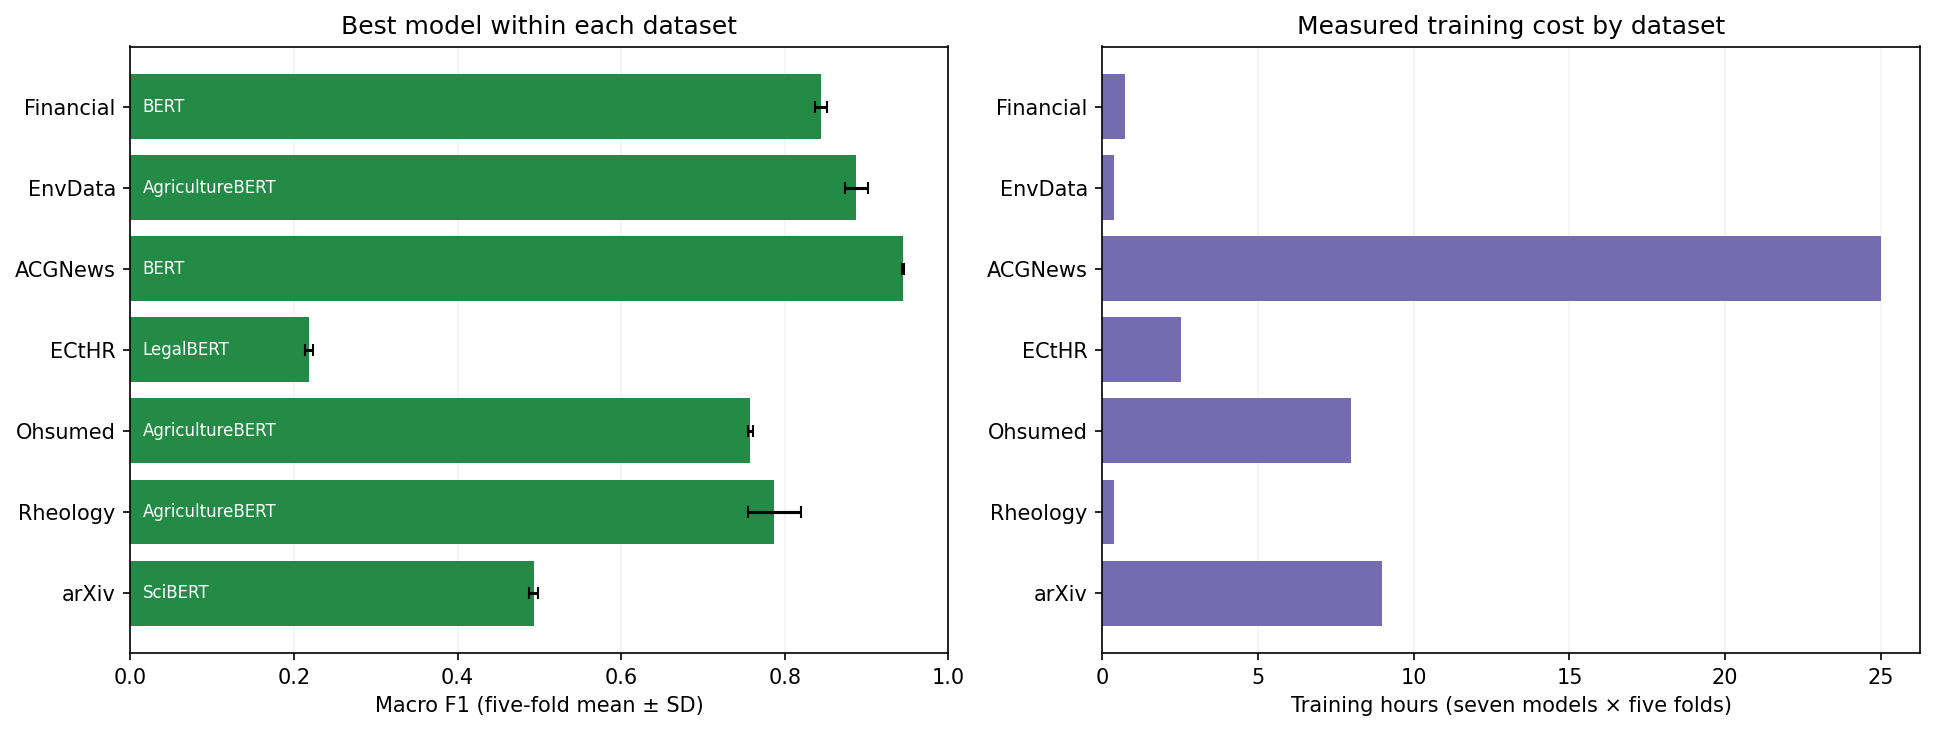

In [1]:
import io
import matplotlib.pyplot as plt
from IPython.display import Image

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(best_models_df["dataset"], best_models_df["macro_f1_mean"],
             xerr=best_models_df["macro_f1_std"], color="#238b45", capsize=3)
axes[0].invert_yaxis()
axes[0].set_xlim(0,1)
axes[0].set_xlabel("Macro F1 (five-fold mean ± SD)")
axes[0].set_title("Best model within each dataset")
for position, row in best_models_df.iterrows():
    axes[0].text(0.015,position,readable_model(row["model"]),va="center",color="white",fontsize=8)
axes[1].barh(timing_summary_df.index, timing_summary_df["training_hours"],color="#756bb1")
axes[1].invert_yaxis()
axes[1].set_xlabel("Training hours (seven models × five folds)")
axes[1].set_title("Measured training cost by dataset")
for ax in axes:
    ax.grid(axis="x",alpha=.15)
    ax.set_axisbelow(True)
fig.tight_layout()
# 图片直接嵌入 Notebook，不创建多余中间图像文件。
image_buffer = io.BytesIO()
fig.savefig(image_buffer,format="png",dpi=150,bbox_inches="tight")
plt.close(fig)
display(Image(data=image_buffer.getvalue()))


### 如何理解本次结果

- BERT 在 Financial、AG News 上平均 Macro F1 最好；AgricultureBERT 在 EnvData、Ohsumed、Rheology 上最好；LegalBERT 在 ECtHR 上最好；SciBERT 在 arXiv 上最好。
- Ohsumed 的 AgricultureBERT 与 SciBERT 均值差约 0.00066，Rheology 的前几名也较接近且折间波动较大。平均名次不是差异显著的证明。
- ECtHR 与 arXiv 是多标签任务，Macro F1 会受稀有类影响。ECtHR 某些类别不足五个正例，不能保证每个验证折都包含这些类别；评估始终使用固定类别集合。
- 不同数据集难度和标签体系不同，不应把它们的 F1 高低直接解释为模型跨任务优劣。图中每个数据集使用各自最佳模型。
- 新结果来自清洗、合并原 split 后的 8-epoch 五折实验，没有独立保留的原 test。不能把分数变化单独归因于 epoch 数。
- 后续 prediction/grid search 应对齐本次清洁数据和新 F1 目标；旧 uncertainty 实验不应直接替换成这批目标后视为完全一致的新实验。

结果文件：`results/finetuning_8epochs_5fold/fold_results.csv` 与 `model_summary.csv`。本节只读取结果，未启动新训练，未改写模型或数据。
